# Assignment 3 — Sampling Distributions and Estimation

**Course:** STA1

**Group members:** Bibek Paudel, Dora Buruncuk, Supendra Bogati

## Table of contents
1. [Part 1 — Sampling distributions and the CLT](#part1)
2. [Part 2 — Estimating mean sensor error](#part2)
3. [Part 3 — Estimating a false-rejection proportion](#part3)
4. [Part 4 — AI-use and conclusion](#part4)

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

<a id="part1"></a>
# Part 1 — Sampling distributions and the CLT

> Restoration time in a service system is modelled as exponential with population mean and standard
> deviation $\mu=\sigma=60$ minutes. Use this known population model and NumPy's random generator
> with seed 2026 and at least 20,000 repetitions per sample size.

**Model:** $X$ is one restoration time, exponential with $\mu = \sigma = 60$ minutes. $\bar X$ is
the mean of $n$ independent restoration times.

**Population distribution:** the possible values of one restoration time $X$.

**Observed sample:** the $n$ values collected in one study.

**Sampling distribution:** the possible values of $\bar X$ across repeated samples of the same size
$n$. $\bar X$ changes from sample to sample, so it is a random variable.

## a)

> Simulate samples for $n=1,5,20,80$ and store their means. Create a table with $n$, theoretical
> mean, simulated mean of means, theoretical standard error $\sigma/\sqrt n$, and empirical standard
> deviation of the simulated means.

$$E[\bar X] = \mu, \qquad \text{SE}(\bar X) = \text{SD}(\bar X) = \frac{\sigma}{\sqrt n}$$

In [2]:
mu = sigma = 60                  # population mean and SD (minutes)
n_rep = 20_000                   # repeated samples for each n (not the n in sigma/sqrt(n))
sample_sizes = (1, 5, 20, 80)

rng = np.random.default_rng(2026)   # one generator for all of Part 1
means = {}
rows = []
for n in sample_sizes:
    samples = rng.exponential(scale=mu, size=(n_rep, n))   # scale = mean = 1/lambda; one row = one sample
    means[n] = samples.mean(axis=1)                         # one mean per sample
    rows.append({"n": n, "theoretical mean": mu, "simulated mean of means": means[n].mean(),
                 "theoretical SE": sigma / np.sqrt(n), "SD of simulated means": means[n].std(ddof=1)})

pd.DataFrame(rows).set_index("n").round(4)

,theoretical mean,simulated mean of means,theoretical SE,SD of simulated means
n,,,,
1,60,60.3279,60.0000,60.1990
5,60,59.5002,26.8328,26.6836
20,60,59.9367,13.4164,13.3526
80,60,59.9905,6.7082,6.7396


**Interpretation:** for every $n$ the simulated mean of means is close to 60 and the SD of the
simulated means is close to $\sigma/\sqrt n$. The small differences are simulation error.

**SD versus SE:** $\sigma = 60$ is the spread of single restoration times. The SE is the spread of
sample means, so it shrinks as $n$ grows.

## b)

> Create one figure showing the four sampling distributions with density histograms and overlay
> $N(\mu,\sigma^2/n)$. Explain how centre, spread, and shape change and why the normal curve is an
> approximation for this non-normal population.

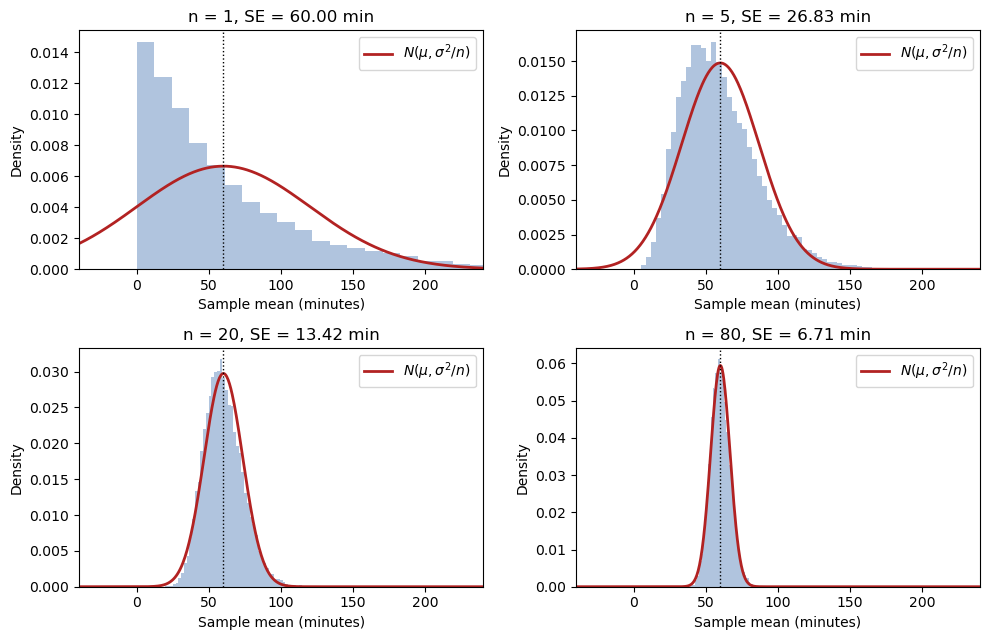

In [3]:
grid = np.linspace(-40, 240, 600)

fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
for ax, n in zip(axes.flat, sample_sizes):
    se = sigma / np.sqrt(n)
    ax.hist(means[n], bins=60, density=True, color="lightsteelblue")
    ax.plot(grid, norm.pdf(grid, loc=mu, scale=se), color="firebrick", lw=2,
            label=r"$N(\mu, \sigma^2/n)$")
    ax.axvline(mu, color="black", ls=":", lw=1)
    ax.set(title=f"n = {n}, SE = {se:.2f} min", xlabel="Sample mean (minutes)", ylabel="Density",
           xlim=(-40, 240))
    ax.legend()

plt.tight_layout()
plt.show()

**Centre:** every histogram is centred at 60 minutes, because $E[\bar X] = \mu$.

**Spread:** it shrinks as $n$ grows, from SE = 60 at $n = 1$ to 6.71 at $n = 80$, because
$\text{SE} = \sigma/\sqrt n$.

**Shape:** $n = 1$ is the exponential population itself, strongly right-skewed with its peak at 0.
The skew weakens as $n$ grows: $n = 5$ is still clearly skewed, $n = 20$ only slightly, and $n = 80$
is close to the normal curve.

**Why the normal curve is an approximation:** the population is exponential, not normal. If it were
normal, $\bar X$ would be exactly normal for every $n$. Here the CLT only gives
$\bar X \approx N(\mu, \sigma^2/n)$ for large $n$, and some right skew remains at every finite $n$.
At $n = 1$ the normal curve even puts 16 % of its probability on negative restoration times.

## c)

> For $n=20$ and $n=80$, estimate $P(\bar X>75)$ by simulation and calculate the CLT approximation.
> Compare the values.

$$P(\bar X > 75) \approx P\left(Z > \frac{75 - \mu}{\sigma/\sqrt n}\right)$$

In [4]:
rows = []
for n in (20, 80):
    se = sigma / np.sqrt(n)
    rows.append({"n": n, "z": (75 - mu) / se,
                 "simulated P(mean > 75)": np.mean(means[n] > 75),   # share of the simulated means above 75
                 "CLT approximation": norm.sf(75, loc=mu, scale=se)})

pd.DataFrame(rows).set_index("n").round(4)

,z,simulated P(mean > 75),CLT approximation
n,,,
20,1.1180,0.1334,0.1318
80,2.2361,0.0186,0.0127


**Comparison:** for $n = 20$ the two values almost agree (0.1334 and 0.1318). For $n = 80$ the
simulation gives 0.0186, about 1.5 times the CLT value of 0.0127. At $n = 80$, 75 minutes lies
further out in the right tail ($z = 2.24$), where the remaining right skew of $\bar X$ matters most,
so the normal curve underestimates the probability. The simulated value is the better description
of this exponential model; the CLT value is a normal shortcut.

## d)

> Find the smallest integer $n$ for which $\operatorname{SE}(\bar X)\le6$ minutes and verify it by
> simulation.

$$\frac{\sigma}{\sqrt n} \le 6 \quad \Rightarrow \quad n \ge \left(\frac{\sigma}{6}\right)^2
= \left(\frac{60}{6}\right)^2 = 100$$

In [5]:
target_se = 6
n_required = int(np.ceil((sigma / target_se)**2))
print("Smallest n:", n_required)
for n in (n_required - 1, n_required):
    print(f"n = {n}: SE = {sigma / np.sqrt(n):.4f} minutes")

means_required = rng.exponential(scale=mu, size=(n_rep, n_required)).mean(axis=1)
print(f"\nSimulation, n = {n_required}: SD of the {n_rep} sample means = {means_required.std(ddof=1):.4f} minutes")

Smallest n: 100
n = 99: SE = 6.0302 minutes
n = 100: SE = 6.0000 minutes

Simulation, n = 100: SD of the 20000 sample means = 6.0635 minutes


**Result:** $n = 100$. At $n = 99$ the SE is 6.03, just above 6. The simulated SD of the sample
means at $n = 100$ is 6.06, close to the theoretical SE of 6. The small difference is simulation
error from using 20,000 repetitions.

## e)

> Generate one sequence of 5,000 observations and plot its running mean. Explain the law of large
> numbers and how this plot differs from a sampling distribution.

$$\bar X_k = \frac{1}{k}\sum_{i=1}^{k} X_i, \qquad k = 1, 2, \dots, 5000$$

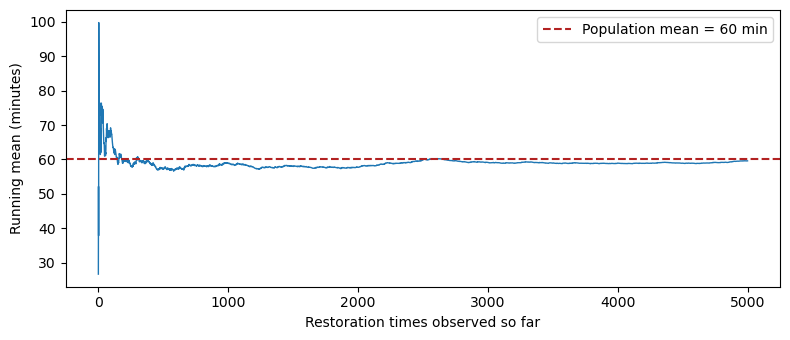

after   10 observations: 76.56 min
after  100 observations: 67.92 min
after 1000 observations: 58.96 min
after 5000 observations: 59.59 min


In [6]:
sequence = rng.exponential(scale=mu, size=5_000)    # one sequence of restoration times
counts = np.arange(1, len(sequence) + 1)            # observations so far
running_mean = np.cumsum(sequence) / counts         # mean after each new observation

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(counts, running_mean, lw=1)
ax.axhline(mu, color="firebrick", ls="--", label="Population mean = 60 min")
ax.set(xlabel="Restoration times observed so far", ylabel="Running mean (minutes)")
ax.legend()
plt.tight_layout()
plt.show()

for k in (10, 100, 1000, 5000):
    print(f"after {k:>4} observations: {running_mean[k - 1]:.2f} min")

**Law of large numbers:** as more independent observations are added, the sample mean gets close to
$\mu$ and stays close: $P(|\bar X_n - \mu| \ge \varepsilon) \to 0$ as $n \to \infty$, for every
$\varepsilon > 0$. Here the running mean jumps around at first (76.56 after 10 observations,
67.92 after 100) and then settles near 60 (59.59 after 5,000). It does not move towards 60 steadily.

**Difference from a sampling distribution:** this plot follows one growing sequence, and each point
reuses all earlier observations. A sampling distribution comes from many independent samples of the
same fixed size $n$ and shows how $\bar X$ varies between them. The LLN says where $\bar X$
settles; the CLT describes the shape of its sampling distribution.

## Scope of the CLT

> State explicitly that the CLT concerns sample means. It neither makes individual restoration times
> normal nor repairs dependence, drift, or unrepresentative sampling.

The CLT concerns sample means, not single observations. Individual restoration times stay
exponential and right-skewed for every $n$; only the distribution of $\bar X$ becomes approximately
normal. The CLT also assumes independent observations from one stable population, so it does not fix
dependent repairs (for example several repairs caused by the same outage), a mean that drifts over
time, or a sample that does not represent the system.